# Email / SMS Spam Detection with Machine Learning
**Oasis Infobyte Internship (Data Science) - Task 4**

**Objective:** In this project I build an NLP classifier that can tell whether a message is spam or ham (a normal, legitimate message). I clean the text, convert it into numbers using TF-IDF, and train a few classifiers to compare them.

## 1. Importing Libraries
First I import everything I need: pandas for the data, `re` and a stemmer for cleaning the text, scikit-learn for TF-IDF and the models, and matplotlib/seaborn for the charts.

In [1]:
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 70

## 2. Loading the Dataset
I am using the SMS Spam Collection dataset (from Kaggle / UCI). The file needs `encoding='latin-1'`, otherwise pandas gives a decoding error. The raw file has the label in column `v1` and the message in `v2`, plus some empty extra columns, so I keep only the first two and rename them to something readable.

In [2]:
df = pd.read_csv('spam.csv', encoding='latin-1')
df = df[['v1', 'v2']]
df.columns = ['label', 'message']
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Data Check and Class Distribution
Now I look at the size of the data, check for missing values and duplicates, and count how many messages are spam and how many are ham.

In [3]:
print('Shape:', df.shape)
print('\nNull values:')
print(df.isnull().sum())
print('\nDuplicate messages:', df.duplicated().sum())

Shape: (5574, 2)

Null values:
label      0
message    0
dtype: int64

Duplicate messages: 403


I found some duplicate messages. Duplicates can leak between the training and test sets and make my scores look better than they really are, so I remove them.

Shape after removing duplicates: (5171, 2)
       count  percentage
label                   
ham     4518       87.37
spam     653       12.63


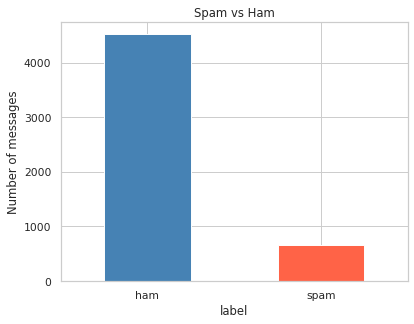

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)

counts = df['label'].value_counts()
percent = df['label'].value_counts(normalize=True) * 100
print(pd.DataFrame({'count': counts, 'percentage': percent.round(2)}))

counts.plot(kind='bar', color=['steelblue', 'tomato'], rot=0, title='Spam vs Ham')
plt.ylabel('Number of messages')
plt.show()

**What I see:** the data is imbalanced. Most messages are ham and only about 12-13% are spam. Because of this, accuracy alone can be misleading (a model that always says "ham" would already get close to 87%). That is why I will also look at precision, recall and F1-score, especially for the spam class.

## 4. Text Preprocessing
Computers can't work with raw text, so I clean it first. My pipeline does the following:
1. Convert to lowercase
2. Remove punctuation, numbers and special characters
3. Remove stopwords (common words like *the*, *is*, *and* that don't help in separating spam from ham)
4. Stemming with the Porter stemmer (for example *winning* and *wins* both become *win*)

In [5]:
stemmer = PorterStemmer()
stop_words = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = text.lower()                          # lowercase
    text = re.sub(r'[^a-z\s]', ' ', text)        # keep only letters
    words = text.split()
    words = [w for w in words if w not in stop_words]   # remove stopwords
    words = [stemmer.stem(w) for w in words]            # stemming
    return ' '.join(words)

df['clean_message'] = df['message'].apply(clean_text)
df[['message', 'clean_message']].head(8)

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",jurong point crazi avail bugi n great world la...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st t...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c say
4,"Nah I don't think he goes to usf, he lives aro...",nah don t think goe usf live
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darl s week s word d like fun tb o...
6,Even my brother is not like to speak with me. ...,brother like speak treat like aid patent
7,As per your request 'Melle Melle (Oru Minnamin...,request mell mell oru minnaminungint nurungu v...


The cleaned messages are shorter and only keep the meaningful root words. I also convert the labels into numbers: ham = 0 and spam = 1.

In [6]:
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})
df[['label', 'label_num']].head()

,label,label_num
0,ham,0
1,ham,0
2,spam,1
3,ham,0
4,ham,0


## 5. Some Quick Visualisations
Before modelling, I check whether spam messages are different in length from ham messages.

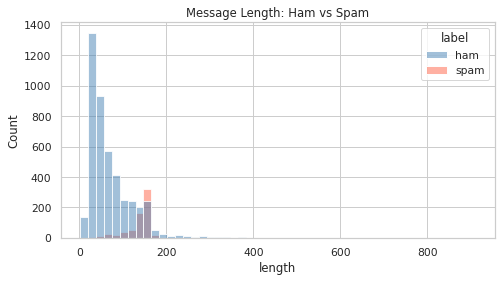

label
ham      70.9
spam    137.7
Name: length, dtype: float64


In [7]:
df['length'] = df['message'].apply(len)
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='length', hue='label', bins=50, palette={'ham': 'steelblue', 'spam': 'tomato'})
plt.title('Message Length: Ham vs Spam')
plt.show()
print(df.groupby('label')['length'].mean().round(1))

Spam messages are clearly longer on average. Spammers usually pack in offers, prices and phone numbers, so length is already a hint, and the words will give the model even more to work with.

### (Bonus) WordClouds
A WordCloud shows the most frequent words in a group of texts. Bigger words appear more often. I make one for spam and one for ham.

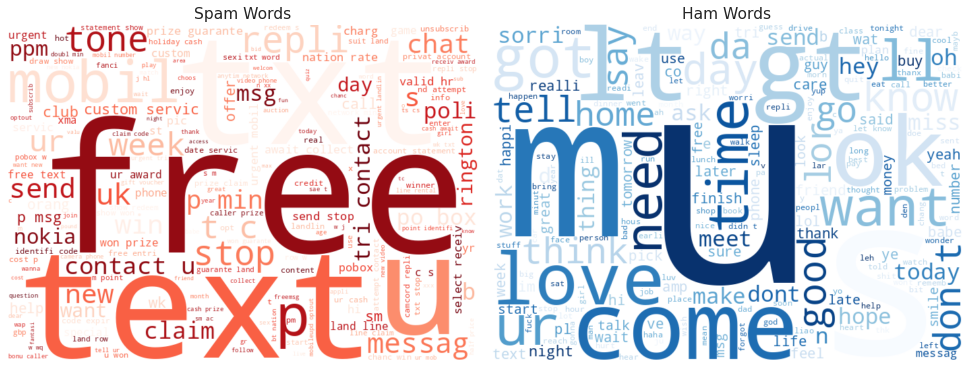

In [8]:
from wordcloud import WordCloud

spam_text = ' '.join(df[df['label'] == 'spam']['clean_message'])
ham_text = ' '.join(df[df['label'] == 'ham']['clean_message'])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, text, title, cmap in zip(axes, [spam_text, ham_text],
                                 ['Spam Words', 'Ham Words'], ['Reds', 'Blues']):
    wc = WordCloud(width=700, height=500, background_color='white', colormap=cmap).generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title, fontsize=16)
    ax.axis('off')
plt.tight_layout()
plt.show()

**What I see:** the spam WordCloud is full of words like *free*, *txt*, *text*, *mobil*, *claim*, *prize*, *repli* and *stop*, which are typical of promotional and scam messages (some words look cut because of stemming, for example *mobil* is *mobile*). The ham WordCloud has everyday chat words like *come*, *know*, *love*, *time*, *like* and *ok*, which is how people normally talk to each other.

## 6. Feature Extraction using TF-IDF
**What is TF-IDF?** TF-IDF stands for *Term Frequency - Inverse Document Frequency*. It gives every word in a message a score that tells how important that word is.

- **Term Frequency (TF):** how often a word appears in a message. A word that appears many times in one message gets a higher score there.
- **Inverse Document Frequency (IDF):** how rare the word is across all messages. Common words that appear everywhere get a low score, and rare, distinctive words get a high score.

**TF-IDF = TF x IDF.** So a word gets a high score when it is frequent in one message but rare overall, like *prize* or *claim* in a spam message. This is better than just counting words, because it reduces the weight of words that appear in every message.

## 7. Train/Test Split
I split the data 80% for training and 20% for testing. I use `stratify` so the spam/ham ratio stays the same in both parts, which matters since the data is imbalanced. I fit the TF-IDF vectorizer **only on the training data** and then use it to transform the test data, so no information from the test set leaks into training.

In [9]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['clean_message'], df['label_num'],
    test_size=0.2, random_state=42, stratify=df['label_num'])

tfidf = TfidfVectorizer(max_features=3000)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print('Training samples:', X_train.shape[0])
print('Test samples:', X_test.shape[0])
print('Number of TF-IDF features:', X_train.shape[1])

Training samples: 4136
Test samples: 1035
Number of TF-IDF features: 3000


## 8. Training the Models
I train three classifiers:
1. **Multinomial Naive Bayes**: the standard choice for text classification
2. **Logistic Regression**: a strong and simple alternative
3. **Linear SVM**: often works very well on TF-IDF features

In [10]:
models = {
    'Multinomial Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Linear SVM': LinearSVC(),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(name, 'trained')

Multinomial Naive Bayes trained
Logistic Regression trained
Linear SVM trained


## 9. Evaluating the Models
For each model I calculate accuracy, precision, recall and F1-score for the spam class, and show the full classification report.

In [11]:
rows = []
for name, y_pred in predictions.items():
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
    })
    print('=' * 60)
    print(name)
    print('=' * 60)
    print(classification_report(y_test, y_pred, target_names=['ham', 'spam']))

results = pd.DataFrame(rows).set_index('Model').round(4)
results

Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       904
        spam       0.99      0.79      0.88       131

    accuracy                           0.97      1035
   macro avg       0.98      0.89      0.93      1035
weighted avg       0.97      0.97      0.97      1035

Logistic Regression
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       904
        spam       0.99      0.72      0.83       131

    accuracy                           0.96      1035
   macro avg       0.98      0.86      0.91      1035
weighted avg       0.96      0.96      0.96      1035

Linear SVM
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       904
        spam       0.99      0.89      0.94       131

    accuracy                           0.99      1035
   macro avg       0.99      0.95      0.97      1035
weighted avg       

,Accuracy,Precision,Recall,F1-score
Model,,,,
Multinomial Naive Bayes,0.9720,0.9904,0.7863,0.8766
Logistic Regression,0.9633,0.9895,0.7176,0.8319
Linear SVM,0.9855,0.9915,0.8931,0.9398


### Confusion Matrices
The confusion matrix shows exactly where each model goes wrong. The top-right box is ham wrongly marked as spam (false positive) and the bottom-left box is spam that slipped through as ham (false negative).

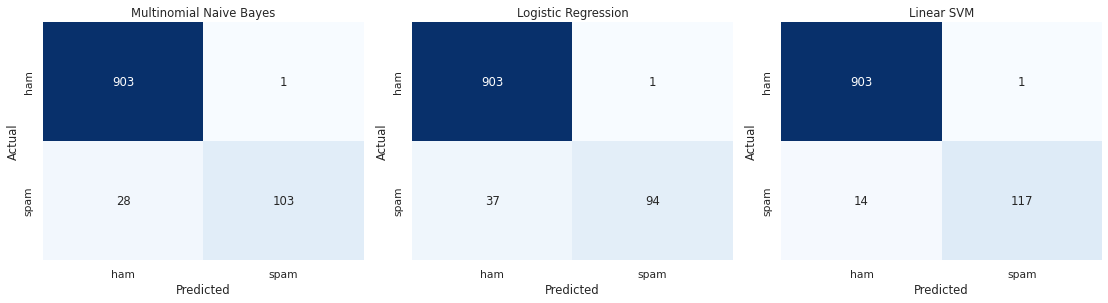

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

### Model Comparison Chart

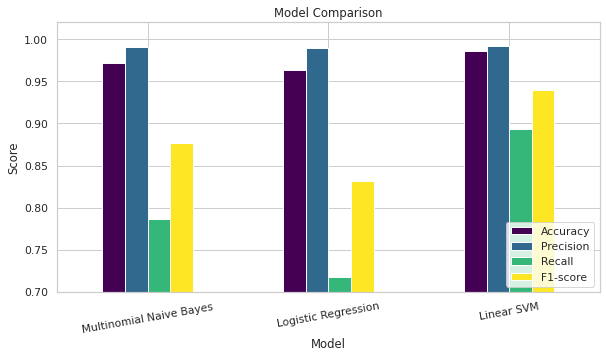

In [13]:
results.plot(kind='bar', figsize=(10, 5), ylim=(0.7, 1.02), rot=10, colormap='viridis')
plt.title('Model Comparison')
plt.ylabel('Score')
plt.legend(loc='lower right')
plt.show()

## 10. Why is Recall Important for Spam Detection?
**Recall** tells us out of all the real spam messages, how many did the model actually catch. Recall = True Positives / (True Positives + False Negatives).

If recall is low, a lot of spam slips through into the inbox. These messages can contain phishing links, scams and fake offers, so missing them can actually cost the user money or their data, and it also defeats the purpose of having a spam filter.

However, recall should not be looked at alone. If I flagged *everything* as spam I would have 100% recall, but real, important messages would be lost. That is why precision matters as well: a false positive (a good message sent to the spam folder) can mean the user misses something important like an OTP or a job email. So the best spam filter keeps **high recall while still keeping precision high**, and the F1-score is a good way to balance the two.

## 11. Best Model and Conclusion
I trained three models and compared them. Here are the test results:

| Model | Accuracy | Precision | Recall | F1-score |
|---|---|---|---|---|
| Multinomial Naive Bayes | 97.2% | 99.0% | 78.6% | 87.7% |
| Logistic Regression | 96.3% | 99.0% | 71.8% | 83.2% |
| **Linear SVM** | **98.6%** | **99.2%** | **89.3%** | **94.0%** |

All three models have very high precision (about 99%), which means they almost never mark a real message as spam. The big difference is in **recall**. Naive Bayes caught about 79% of the spam and Logistic Regression only about 72%, while **Linear SVM caught about 89%** and also had the best accuracy and F1-score.

So I declare **Linear SVM as the best model** for this dataset. Since recall is the most important thing for a spam filter (as I explained above) and the SVM has the best recall without losing precision, it is the safest choice. Multinomial Naive Bayes is still a good and very fast baseline, but in my run it missed more spam.

Things I would try to improve it further: using n-grams (word pairs like *free entry*), tuning the class weights because the data is imbalanced, or lowering the decision threshold to push recall even higher.

## 12. Testing with New Messages
Finally, I try the best model on a few messages I wrote myself to see how it behaves on unseen text.

In [14]:
best_name = results['F1-score'].idxmax()
best_model = models[best_name]

samples = [
    'Congratulations! You have won a free prize. Call now to claim your reward',
    'Hey, are we meeting for lunch tomorrow?',
    'URGENT! Your account has been selected for a cash offer, text WIN to 80082',
    'Please send me the notes from yesterday class',
]
sample_vec = tfidf.transform([clean_text(s) for s in samples])
preds = best_model.predict(sample_vec)

print('Best model:', best_name, '\n')
for s, p in zip(samples, preds):
    print(('SPAM' if p == 1 else 'HAM ').ljust(5), '|', s)

Best model: Linear SVM 

SPAM  | Congratulations! You have won a free prize. Call now to claim your reward
HAM   | Hey, are we meeting for lunch tomorrow?
SPAM  | URGENT! Your account has been selected for a cash offer, text WIN to 80082
HAM   | Please send me the notes from yesterday class
